# 03 - Training: EfficientNet-B0 on the cleaned APTOS dataset

**Goal:** train a diabetic retinopathy grading model on the deduplicated data (2,803 train / 701 validation) and evaluate it on the untouched validation set.

**Configuration (chosen from the first version of the project, which overfit):** pretrained EfficientNet-B0, weighted sampler with 1/sqrt(count) weights, label smoothing 0.1, AdamW with weight decay 1e-2, cosine learning-rate decay, 15 epochs with early stopping, mixed precision. Hardware: RTX 3070 Laptop GPU.

## 1. Environment setup and GPU check
We make `src/` importable, enable autoreload, fix the random seeds, and confirm that PyTorch sees the GPU.

In [35]:
import sys, os, time, random
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from src.dataset import get_dataloaders, IMAGENET_MEAN, IMAGENET_STD
from src.model import create_model
from src.engine import train_one_epoch, evaluate

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
True NVIDIA GeForce RTX 3070 Laptop GPU


**Interpretation:** `True NVIDIA GeForce RTX 3070 Laptop GPU`: PyTorch uses the GPU, and the seeds are fixed for reproducibility. Note: the sampler and augmentation are random, so results can vary slightly between runs even with fixed seeds.

## 2. Data loaders and tensor shapes
`get_dataloaders` builds a training loader (augmentation + weighted sampling) and a validation loader (no augmentation, no resampling). We check sizes and the shape of one batch.

In [36]:
BATCH_SIZE = 16
train_loader, val_loader, train_ds, val_ds = get_dataloaders(batch_size=BATCH_SIZE, num_workers=0)
print("Train / val images:", len(train_ds), len(val_ds))

images, labels = next(iter(train_loader))
print(images.shape, images.dtype)
print(labels)

Train / val images: 2803 701
torch.Size([16, 3, 512, 512]) torch.float32
tensor([3, 1, 0, 3, 2, 0, 0, 1, 1, 3, 2, 0, 0, 4, 0, 4])


**Interpretation:** 2,803 training and 701 validation images, matching the saved split. A batch has shape [16, 3, 512, 512] in `float32`, the format EfficientNet expects. `num_workers=0` is used here only to keep error messages readable.

## 3. What the network receives (augmented training images)
We undo the normalization to display the tensors. This shows the effect of the random flips, rotations, shifts, zoom and color jitter.

In [ ]:
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"grade {lab.item()}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** 

the images are retinas with natural orange/red colors, so the normalization round-trip and BGR/RGB handling are correct. Augmentation is visible: rotations, shifts and zoom, with black corners where the rotation leaves empty space (expected, harmless). Lesions (exudates, hemorrhages) and vessels remain clearly visible, so the augmentation strength does not destroy diagnostic information. The bright arc in the top-right of one grade 1 image appears to come from the source photograph.

## 4. How does the weighted sampler change what the model sees?
Training grades are strongly imbalanced. The sampler draws images with probability proportional to 1/sqrt(count of their grade), so rare grades are favored without forcing a perfectly balanced epoch. We count what one epoch contains.

In [38]:
real = np.bincount(train_ds.labels)
drawn = np.bincount(train_ds.labels[list(train_loader.sampler)], minlength=5)
print("Real training images per grade:", real)
print("Samples drawn in one epoch:    ", drawn)

Real training images per grade: [1437  270  737  142  217]
Samples drawn in one epoch:     [987 402 720 314 380]


**Interpretation:** 

the real training set has 1437 / 270 / 737 / 142 / 217 images per grade. With 1/sqrt weights, an epoch should contain roughly 982 / 426 / 704 / 309 / 382 draws (random, so exact values vary), against 1437 / 270 / 737 / 142 / 217 without a sampler. Rare grades are oversampled with replacement (grade 3: 142 unique images drawn about 2.2 times each on average), and random augmentation makes each repeated copy different. The validation loader is not resampled or augmented.

## 5. Model, loss and optimizer
Pretrained EfficientNet-B0 (transfer learning) with a new 5-class output layer. Loss: cross-entropy with label smoothing 0.1 (less overconfident predictions). Optimizer: AdamW, learning rate 3e-4, weight decay 1e-2. Cosine decay over 15 epochs. Mixed precision.

In [39]:
EPOCHS = 15
train_loader, val_loader, train_ds, val_ds = get_dataloaders(batch_size=BATCH_SIZE, num_workers=4)

model = create_model().to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

print("Parameters:", round(sum(p.numel() for p in model.parameters()) / 1e6, 2), "million")

Parameters: 4.01 million


**Interpretation:** about 4.01 million parameters (EfficientNet-B0 with a 5-class head), small enough to train comfortably on the RTX 3070 at batch size 16 and 512x512. The loaders are recreated with `num_workers=4` for training speed.

## 6. Training loop (15 epochs, early stopping)
Each epoch trains on the augmented, resampled training set and evaluates on the untouched validation set. We track loss, accuracy, QWK, macro AUC, referable-DR AUC (grade 2 or higher) and recall per grade. The best model by validation QWK is saved; training stops if QWK does not improve for 5 epochs.

In [40]:
os.makedirs("../models", exist_ok=True)
history, best_qwk, patience, bad = [], -1, 5, 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
    m = evaluate(model, val_loader, criterion, device)
    scheduler.step()

    history.append({"epoch": epoch, "train_loss": train_loss,
                    **{k: m[k] for k in ["loss", "acc", "qwk", "auc_macro", "auc_referable"]}})
    print(f"Epoch {epoch:2d} | train {train_loss:.3f} | val {m['loss']:.3f} | acc {m['acc']:.3f} | "
          f"QWK {m['qwk']:.3f} | AUC {m['auc_macro']:.3f} | ref AUC {m['auc_referable']:.3f} | {time.time()-t0:.0f}s")
    print("   recall per grade:", m["sensitivity"])

    if m["qwk"] > best_qwk:
        best_qwk, bad = m["qwk"], 0
        torch.save(model.state_dict(), "../models/efficientnet_b0_v2_best.pth")
        print("   saved new best model")
    else:
        bad += 1
        if bad >= patience:
            print(f"Early stopping: no QWK improvement for {patience} epochs")
            break

pd.DataFrame(history).to_csv("../models/history_v2.csv", index=False)

Epoch  1 | train 1.435 | val 0.865 | acc 0.786 | QWK 0.863 | AUC 0.925 | ref AUC 0.976 | 66s
   recall per grade: [0.953 0.574 0.681 0.457 0.519]
   saved new best model


Epoch  2 | train 0.991 | val 0.847 | acc 0.806 | QWK 0.887 | AUC 0.930 | ref AUC 0.979 | 36s
   recall per grade: [0.936 0.397 0.892 0.171 0.574]
   saved new best model


Epoch  3 | train 0.863 | val 0.772 | acc 0.835 | QWK 0.898 | AUC 0.939 | ref AUC 0.982 | 43s
   recall per grade: [0.983 0.721 0.762 0.543 0.426]
   saved new best model


Epoch  4 | train 0.788 | val 0.770 | acc 0.846 | QWK 0.903 | AUC 0.934 | ref AUC 0.981 | 46s
   recall per grade: [0.972 0.706 0.8   0.371 0.648]
   saved new best model


Epoch  5 | train 0.723 | val 0.763 | acc 0.852 | QWK 0.919 | AUC 0.932 | ref AUC 0.982 | 48s
   recall per grade: [0.978 0.588 0.865 0.371 0.611]
   saved new best model


...

Epoch 10 | train 0.527 | val 0.760 | acc 0.856 | QWK 0.922 | AUC 0.925 | ref AUC 0.975 | 52s
   recall per grade: [0.975 0.721 0.816 0.486 0.611]


Epoch 11 | train 0.513 | val 0.757 | acc 0.853 | QWK 0.924 | AUC 0.936 | ref AUC 0.976 | 50s
   recall per grade: [0.978 0.721 0.784 0.457 0.685]


Epoch 12 | train 0.512 | val 0.761 | acc 0.856 | QWK 0.924 | AUC 0.929 | ref AUC 0.977 | 51s
   recall per grade: [0.978 0.75  0.789 0.343 0.741]


Epoch 13 | train 0.498 | val 0.753 | acc 0.856 | QWK 0.925 | AUC 0.925 | ref AUC 0.976 | 51s
   recall per grade: [0.975 0.721 0.805 0.429 0.685]


Epoch 14 | train 0.485 | val 0.751 | acc 0.860 | QWK 0.925 | AUC 0.924 | ref AUC 0.977 | 56s
   recall per grade: [0.975 0.691 0.838 0.4   0.685]
Early stopping: no QWK improvement for 5 epochs


**Interpretation:** 

Training stopped by early stopping after 14 of 15 epochs (no QWK improvement for 5 epochs); the best model is epoch 9 (validation QWK 0.926). One epoch takes about 36 to 66 s. QWK rose from 0.863 (epoch 1) to 0.926 (epoch 9) and stayed between 0.922 and 0.925 afterwards. Recall per grade fluctuated strongly between epochs, especially for rare grades (grade 3: 0.17 at epoch 2, 0.54 at epoch 3, 0.23 at epoch 8). With only 35 validation images in that grade, single-epoch values are not reliable.

## 7. Training curves
Loss (train vs validation), validation QWK, and validation AUC (macro and referable).

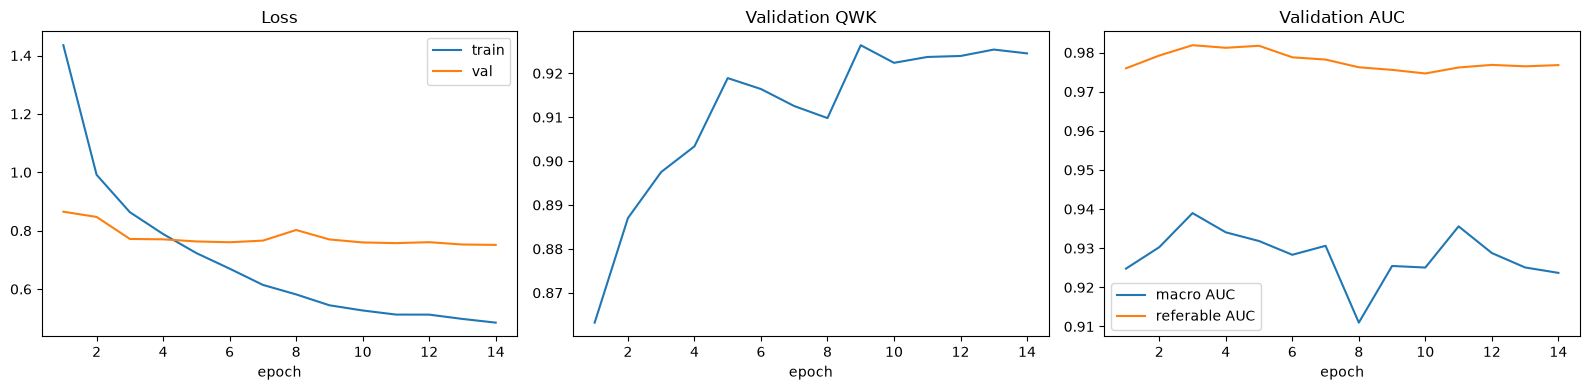

In [41]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train"); axes[0].plot(hist.epoch, hist.loss, label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(hist.epoch, hist.qwk); axes[1].set_title("Validation QWK")
axes[2].plot(hist.epoch, hist.auc_macro, label="macro AUC"); axes[2].plot(hist.epoch, hist.auc_referable, label="referable AUC")
axes[2].set_title("Validation AUC"); axes[2].legend()
for a in axes: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Interpretation:** 

The validation loss falls from 0.865 to about 0.75 and stays flat from epoch 5 to 14, without the U-shape seen in the first version, so overfitting is controlled. Training loss ends at 0.485; part of the remaining gap comes from the label-smoothing loss floor (about 0.39), augmentation and dropout, which are active only during training. QWK is stable around 0.92 over the last epochs. Macro AUC fluctuates between 0.911 and 0.939 (dip at epoch 8), while referable AUC stays between 0.975 and 0.982.

## 8. Evaluation of the best model on the validation set
We reload the best saved weights and compute all metrics, the recall per grade, the referable-DR sensitivity and specificity (grade 2 or higher), and the confusion matrix.

{'acc': 0.862, 'qwk': 0.926, 'auc_macro': 0.925, 'auc_referable': 0.976}
Recall per grade: [0.972 0.765 0.816 0.486 0.648]
Referable DR sensitivity: 0.898 (missed 28 of 274)
Referable DR specificity: 0.965 (false alarms 15 of 427)


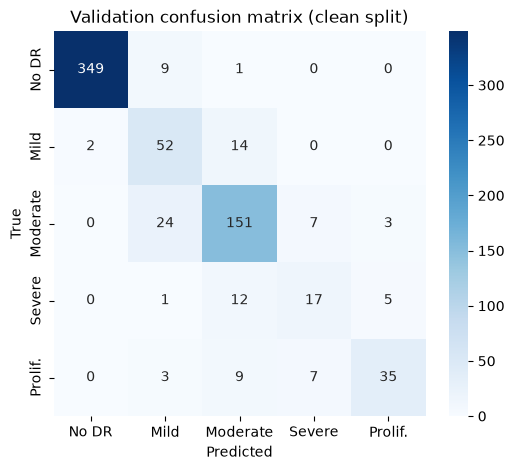

In [42]:
model.load_state_dict(torch.load("../models/efficientnet_b0_v2_best.pth"))
m = evaluate(model, val_loader, criterion, device)
print({k: round(v, 3) for k, v in m.items() if k in ["acc", "qwk", "auc_macro", "auc_referable"]})
print("Recall per grade:", m["sensitivity"])

cm = m["confusion"]
tp = cm[2:, 2:].sum(); fn = cm[2:, :2].sum()
tn = cm[:2, :2].sum(); fp = cm[:2, 2:].sum()
print("Referable DR sensitivity:", round(tp / (tp + fn), 3), f"(missed {fn} of {tp + fn})")
print("Referable DR specificity:", round(tn / (tn + fp), 3), f"(false alarms {fp} of {tn + fp})")

names = ["No DR", "Mild", "Moderate", "Severe", "Prolif."]
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Validation confusion matrix (clean split)")
plt.show()

**Interpretation (best model = epoch 9, validation set, n = 701)**
- Accuracy 0.862, **QWK 0.926**, macro AUC 0.925, referable AUC 0.976.
- **Referable DR (grade 2 or higher): sensitivity 0.898 (28 of 274 missed), specificity 0.965 (15 false alarms out of 427).**
- Recall per grade: No DR 0.972, Mild 0.765, Moderate 0.816, Severe 0.486, Proliferative 0.648.
- Main confusions: 24 Moderate images are predicted Mild (13%), which causes most missed referable patients; Severe and Proliferative are often predicted Moderate (21 of 89). 64 of 89 grade 3+ cases are found.
- **Limitations:** the best epoch was selected on this validation set, so the figures are slightly optimistic; grades 3 and 4 have only 35 and 54 validation images, so their recall is very uncertain; all results come from one dataset.
- **Comparison with the first version** (QWK 0.915, referable sensitivity 0.970): not directly comparable, because the first validation set contained images duplicated in training and conflicting labels. The drop in referable sensitivity is mainly due to Moderate images predicted as Mild. The referral threshold will be re-examined (section 9).

## 9. Adjusting the referral threshold

By default, a patient is referred when the most likely grade is 2 or higher. Instead, we can flag a patient as referable when the summed probability of grades 2 to 4 exceeds a threshold. Lowering the threshold catches more patients who need referral (higher sensitivity) at the cost of more false alarms (lower specificity). We measure this trade-off on the validation set (274 referable, 427 non-referable patients).

In [43]:
probs, y = m["probs"], m["y_true"]
p_ref = probs[:, 2:].sum(axis=1)        # probability of grade 2 or higher
is_ref = y >= 2

print("threshold | sensitivity | specificity | missed | false alarms")
for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    pred = p_ref >= t
    tp = (pred & is_ref).sum(); fn = (~pred & is_ref).sum()
    tn = (~pred & ~is_ref).sum(); fp = (pred & ~is_ref).sum()
    print(f"   {t:.2f}   |    {tp/(tp+fn):.3f}    |    {tn/(tn+fp):.3f}    |   {fn:3d}  |   {fp:3d}")

threshold | sensitivity | specificity | missed | false alarms
   0.50   |    0.920    |    0.965    |    22  |    15
   0.40   |    0.945    |    0.953    |    15  |    20
   0.30   |    0.956    |    0.939    |    12  |    26
   0.20   |    0.971    |    0.911    |     8  |    38
   0.10   |    0.993    |    0.768    |     2  |    99
   0.05   |    0.993    |    0.492    |     2  |   217


**Interpretation (best model, validation set: 274 referable, 427 non-referable patients)**

| Threshold | Missed | False alarms | Sensitivity | Specificity |
|---|---|---|---|---|
| 0.50 | 22 | 15 | 0.920 | 0.965 |
| 0.40 | 15 | 20 | 0.945 | 0.953 |
| 0.30 | 12 | 26 | 0.956 | 0.939 |
| 0.20 | 8 | 38 | 0.971 | 0.911 |
| 0.10 | 2 | 99 | 0.993 | 0.768 |
| 0.05 | 2 | 217 | 0.993 | 0.492 |

- **Summed probability beats the top-choice rule:** at 0.50 it misses 22 referable patients versus 28 for the most-likely-grade rule in section 8, with the same 15 false alarms.
- Lowering the threshold raises sensitivity at the cost of specificity. Down to 0.2, each extra patient caught costs about 1 to 3 false alarms (14 more patients caught between 0.5 and 0.2, for 23 more false alarms). Below 0.2 the cost rises sharply (about 10 false alarms per extra catch at 0.1, and no gain at all at 0.05).
- **Candidate threshold: 0.2** (sensitivity 0.971, specificity 0.911; 87.5% of flagged patients truly need referral). A threshold of 0.3 is a more conservative alternative (12 missed, 26 false alarms).
- **Limitations:** the threshold was explored on the same validation set used for model selection, so the gain is optimistic and rests on a few patients; it must be confirmed on an external dataset. The proportion of referable patients in APTOS (39%) is far higher than in a real screening population, so false alarms would weigh more in practice. Two referable patients are missed at every threshold down to 0.05.

### 9b. The two patients missed at every threshold

Two referable patients keep a summed probability below 0.05, so no threshold recovers them. We look at their images to see whether the cause is visible.

In [44]:
import cv2
idx = np.where(is_ref & (p_ref < 0.05))[0]
print("Validation rows:", idx, "| probabilities:", p_ref[idx].round(3), "| true grades:", y[idx])

fig, axes = plt.subplots(1, len(idx), figsize=(6 * len(idx), 6))
axes = np.atleast_1d(axes)
for ax, i in zip(axes, idx):
    code = val_ds.df.iloc[i]["id_code"]
    ax.imshow(cv2.cvtColor(cv2.imread(f"../data/processed_512/{code}.png"), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{code} | true grade {y[i]} | p(referable) = {p_ref[i]:.3f}")
    ax.axis("off")
plt.show()

Validation rows: [  9 277] | probabilities: [0.027 0.036] | true grades: [4 2]


In [ ]:
import cv2, matplotlib.pyplot as plt
for code in ["03a7f4a5786f", "6d3d1fe6c32a"]:
    img = cv2.cvtColor(cv2.imread(f"../data/train_images/{code}.png"), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8)); plt.imshow(img); plt.axis("off")
    plt.title(f"{code} (raw, {img.shape[1]}x{img.shape[0]})"); plt.show()

**Interpretation (the two patients missed at every threshold)**

Two referable patients keep a summed probability below 0.05 (p = 0.027 for a grade 4 image, p = 0.036 for a grade 2 image), so no threshold recovers them. Visual inspection of the processed images does not make the cause clear. The grade 4 image shows no obvious large hemorrhages or exudate clusters at this resolution, but proliferative disease can be subtle. The grade 2 image shows a few dark red spots near the periphery, together with uneven lighting, blur and a stretched shape. These cases are consistent with either label noise (already documented in this dataset through contradictory duplicate labels) or genuine model failures. They were **not** removed or relabelled. They were not reviewed by a clinician, so no conclusion is drawn about the correct grade.

## Summary

| Aspect | Result |
|---|---|
| Data | 2,803 train / 701 validation, deduplicated, no overlap by id or hash |
| Model | EfficientNet-B0 pretrained, 4.01 M parameters, mixed precision; weights saved as `efficientnet_b0_v2_best.pth` |
| Settings | weighted sampler 1/sqrt(count), label smoothing 0.1, weight decay 1e-2, cosine learning rate; early stopping stopped training after 14 of 15 epochs |
| Overfitting | controlled: validation loss flat from epoch 5 to 14 |
| Best model | epoch 9: QWK 0.926, accuracy 0.862, macro AUC 0.925 |
| Referable DR, most likely grade is 2 or higher | sensitivity 0.898 (28 of 274 missed), specificity 0.965 (15 false alarms) |
| Referable DR, summed probability of grades 2 to 4 at threshold 0.5 | sensitivity 0.920 (22 missed), specificity 0.965 (15 false alarms), AUC 0.976 |
| Referable DR, candidate threshold 0.2 | sensitivity 0.971 (8 missed), specificity 0.911 (38 false alarms) |
| Weak points | Moderate predicted as Mild (24 of 185); Severe recall 0.486 (35 images); Proliferative recall 0.648 (54 images); 2 referable patients missed at every threshold |

**Limitations:** the best epoch and the threshold were chosen on the validation set, so the figures are slightly optimistic; very few severe cases (35); 39% of validation patients are referable, far above a real screening population, so false alarms would weigh more in practice; the two always-missed cases were not reviewed by a clinician; single dataset. The first version of the project was evaluated on a split with duplicate leakage, so its scores are preliminary and are not compared with these.

**Next:** Grad-CAM explainability, then external validation of `efficientnet_b0_v2_best.pth` on an independent dataset, which is where the threshold will be confirmed or rejected.